# 04 · Why did it say that? Explaining KNN with neighbours, SHAP and LIME

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/KNN_IRIS_classification/blob/main/notebooks/04_explaining_knn_with_shap_and_lime.ipynb)

**After this notebook you will be able to** explain one KNN prediction in three ways (its neighbours, SHAP, LIME), explain which measurements matter overall, and say honestly when explanations agree and when they do not.

| | |
|---|---|
| Who it is for | Anyone who finished notebook `02` (notebook `03` is optional). |
| Time | About 45 minutes to read; the code runs in about 20 seconds on a CPU. |
| Random seed | `42` everywhere (LIME and permutation importance get explicit seeds). |
| New packages | `shap` and `lime` (pinned in `requirements.txt`). |

## 1. The big question

Our model named 28 of 30 test flowers correctly and got two wrong. For a person who has to *trust* or *check* the model, the number 28/30 is not enough. They ask: **why did it say "versicolor" for this particular flower?** That is the idea of an *explanation*, and it matters whenever a prediction affects a decision.

## 2. Intuition first: three kinds of "because"

Suppose a friend recommends a restaurant. You could ask for different kinds of reasons:

1. **"Because of these similar cases."** *You loved these three places, and this one is like them.* For KNN this is **free**: its decision *is* a vote of the nearest flowers. We just show them.
2. **"Because of what matters overall."** *Price and distance matter most to you, the colour of the menu hardly at all.* For a model this is **global feature importance**. We use *permutation importance*: shuffle one column, and see how much accuracy drops.
3. **"Because of what mattered for this one decision."** *This time, the price pushed us toward it and the distance pushed us away.* This is a **local attribution**. We use two popular tools: **SHAP** (a fair split of the credit among the features) and **LIME** (a simple straight-line model fitted around this one flower).

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/KNN_IRIS_classification.git"], check=True)
    os.chdir("KNN_IRIS_classification/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.iris_knn import (SEED, FEATURES, CLASSES, load_iris_frame, split_data,
                          scatter_species, plot_decision_regions, save_figure)

np.random.seed(SEED)               # fixed seed: you will get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*IProgress.*")   # progress-bar notice from tqdm, harmless

import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.inspection import permutation_importance

from src.iris_knn import make_model

df = load_iris_frame()
x_train, x_test, y_train, y_test = split_data(df, test_size=0.2, seed=SEED)
model = make_model(k=3).fit(x_train, y_train)           # the model chosen in notebook 02
classes = list(model.classes_)

predictions = model.predict(x_test)
mistakes = np.where(predictions != y_test.to_numpy())[0]
print("test accuracy:", round(model.score(x_test, y_test), 3))
for position in mistakes:
    print(f"  test row {x_test.index[position]}: truth = {y_test.iloc[position]}, prediction = {predictions[position]}")

test accuracy: 0.933
  test row 138: truth = virginica, prediction = versicolor
  test row 134: truth = virginica, prediction = versicolor


Two flowers are wrong, both *virginica* named *versicolor*: the two species that overlap. We will study the first one in detail. Let us look at it.

In [3]:
case = int(mistakes[0])                                  # position inside the test set
flower = x_test.iloc[[case]]
print("the flower:")
print(flower.round(2).to_string(index=True))
print("truth:", y_test.iloc[case], "| prediction:", predictions[case])
print("model probabilities:", dict(zip(classes, model.predict_proba(flower)[0].round(3))))

the flower:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
138                6.0               3.0                4.8               1.8
truth: virginica | prediction: versicolor
model probabilities: {'setosa': np.float64(0.0), 'versicolor': np.float64(0.667), 'virginica': np.float64(0.333)}


The model gives *versicolor* a probability of two thirds and *virginica* one third. With `k=3` that means two of the three neighbours voted for *versicolor*. Let us see them.

## 3. Explanation 1: the neighbours themselves

In [4]:
scaler = model.named_steps["standardscaler"]
knn = model.named_steps["kneighborsclassifier"]
distances, rows = knn.kneighbors(scaler.transform(flower))

neighbours = x_train.iloc[rows[0]].assign(species=y_train.iloc[rows[0]].to_numpy(),
                                          distance=distances[0].round(3))
neighbours

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,distance
149,5.9,3.0,5.1,1.8,virginica,0.208
70,5.9,3.2,4.8,1.8,versicolor,0.466
78,6.0,2.9,4.5,1.5,versicolor,0.485


The table is the whole explanation: the flower's nearest neighbour is a *virginica* (distance 0.21), and the next two are *versicolor* (0.47 and 0.49). Two against one, so *versicolor* wins. (Distances are measured on the standardised features, as in notebook 02.)

Note also what the table tells us about the *mistake*: the nearest flower had the right answer, but `k=3` outvoted it. That is an interesting finding that no other tool would hand us so directly.

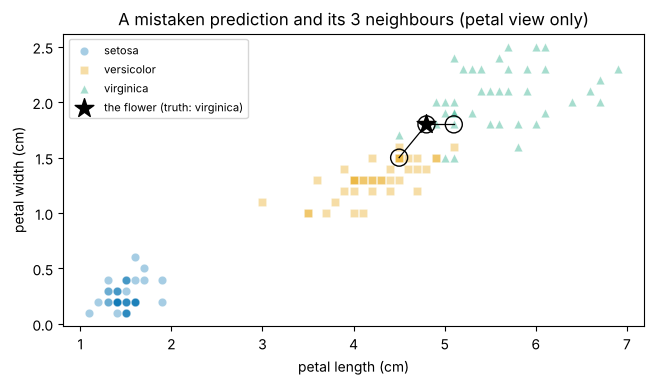

In [5]:
fx, fy = "petal length (cm)", "petal width (cm)"
fig, ax = plt.subplots(figsize=(7.5, 3.8))
scatter_species(ax, x_train.assign(species=y_train), fx, fy, alpha=0.35)
for _, row in neighbours.iterrows():
    ax.plot([flower[fx].iloc[0], row[fx]], [flower[fy].iloc[0], row[fy]], color="black", linewidth=0.9)
    ax.scatter([row[fx]], [row[fy]], s=150, facecolor="none", edgecolor="black")
ax.scatter(flower[fx], flower[fy], marker="*", s=200, color="black", label="the flower (truth: virginica)", zorder=5)
ax.set_title("A mistaken prediction and its 3 neighbours (petal view only)")
ax.legend(fontsize=8, loc="upper left")
save_figure(fig, "04_neighbours_of_a_mistake.png")
plt.show()

*Figure 1. What to notice:* the flower sits in the overlap zone of *versicolor* and *virginica*. The map shows only two of the four measurements, so the circled neighbours need not look the closest on this picture; the distance used four standardised measurements.

## 4. Explanation 2: which measurements matter overall?

**Permutation importance** answers: *if I scramble this column, how much does the accuracy drop?* A big drop means the model relied on that measurement. We use the test set and repeat the shuffle 30 times.

**Predict first:** from notebook 01's pictures, which two measurements do you expect to matter most?

In [6]:
importance = permutation_importance(model, x_test, y_test, n_repeats=30, random_state=SEED)
perm = pd.DataFrame({"mean accuracy drop": importance.importances_mean,
                     "spread": importance.importances_std}, index=FEATURES).round(3)
perm.sort_values("mean accuracy drop", ascending=False)

,mean accuracy drop,spread
petal width (cm),0.260,0.067
petal length (cm),0.221,0.085
sepal width (cm),0.019,0.044
sepal length (cm),0.004,0.027


The two *petal* measurements cause drops of about 0.2 to 0.3; the two *sepal* measurements almost nothing. The spreads are large (the test set has only 30 flowers), but the gap between petal and sepal is clear.

## 5. A little math: SHAP and LIME

**SHAP** gives each feature $i$ a number $\phi_i$: its *fair share* of the credit for the difference between this prediction and an average one. The definition comes from game theory (Shapley values):

$$\phi_i = \sum_{S \subseteq F \setminus \{i\}} \frac{|S|!\,(|F|-|S|-1)!}{|F|!}\,\big[f(S \cup \{i\}) - f(S)\big]$$

- $F$ is the set of all four features, $S$ is a team of features *without* $i$, and $f(S)$ is the model's output when only the features in $S$ are known (the others are replaced by typical values from background data).
- The bracket is *how much feature $i$ adds* when it joins team $S$; the fraction averages that over all possible orders in which features join.
- The shares add up: $f(x) = \text{base value} + \sum_i \phi_i$. We will check this numerically.

**LIME** takes a different route: it creates many small variations of the flower, asks the model about each one, and fits a *simple weighted linear model* that mimics the model only **near this flower**. The weights of that simple model are the explanation. LIME uses random variations, so we fix a seed.

## 6. Explanation 3: SHAP

In [7]:
def predict_probabilities(values):
    """The model as a plain function from numbers to class probabilities."""
    return model.predict_proba(pd.DataFrame(values, columns=FEATURES))

background = shap.kmeans(x_train, 10)                   # 10 typical flowers summarise the training data
explainer = shap.KernelExplainer(predict_probabilities, background)
shap_values = np.array(explainer.shap_values(x_test, silent=True))   # shape: flowers x features x classes
print("shap values shape (flowers, features, classes):", shap_values.shape)
print("base values (average prediction per class):", dict(zip(classes, np.round(explainer.expected_value, 3))))

shap values shape (flowers, features, classes): (30, 4, 3)
base values (average prediction per class): {'setosa': np.float64(0.333), 'versicolor': np.float64(0.364), 'virginica': np.float64(0.303)}


The *base value* is the average prediction on the background data. Now the sanity check: base value plus the four SHAP numbers must equal the model's own probabilities for our flower.

In [8]:
rebuilt = explainer.expected_value + shap_values[case].sum(axis=0)
print("base + sum of SHAP :", dict(zip(classes, rebuilt.round(3))))
print("model probabilities:", dict(zip(classes, model.predict_proba(flower)[0].round(3))))

base + sum of SHAP : {'setosa': np.float64(0.0), 'versicolor': np.float64(0.667), 'virginica': np.float64(0.333)}
model probabilities: {'setosa': np.float64(0.0), 'versicolor': np.float64(0.667), 'virginica': np.float64(0.333)}


They agree. SHAP is an exact bookkeeping of the prediction. Next, the same flower: which measurement pushed toward which species?

In [9]:
local = pd.DataFrame(shap_values[case], index=FEATURES, columns=classes).round(3)
local[["versicolor", "virginica"]]

,versicolor,virginica
sepal length (cm),0.132,-0.092
sepal width (cm),0.116,-0.069
petal length (cm),0.116,0.012
petal width (cm),-0.061,0.180


Read the two columns separately. For the probability of *versicolor* the three first features push **up** and the petal width pushes slightly **down**. For *virginica* it is the other way round: **petal width is the one strong push toward the true species (+0.18)**, while the sepal measurements push against it.

So SHAP's story for this flower: the two sepal measurements and the petal length pushed toward *versicolor*, and only the petal width pushed strongly toward the true species, *virginica*.

## 7. Explanation 4: LIME

In [10]:
lime_explainer = LimeTabularExplainer(x_train.to_numpy(), feature_names=FEATURES, class_names=classes,
                                      discretize_continuous=True, random_state=SEED)
versicolor = classes.index("versicolor")
lime_explanation = lime_explainer.explain_instance(flower.to_numpy()[0], predict_probabilities,
                                                   num_features=4, labels=[versicolor], num_samples=5000)
lime_table = pd.DataFrame(lime_explanation.as_list(label=versicolor), columns=["condition", "weight"]).round(3)
lime_table

,condition,weight
0,4.25 < petal length (cm) <= 5.10,0.101
1,1.30 < petal width (cm) <= 1.80,0.077
2,2.80 < sepal width (cm) <= 3.00,0.053
3,5.75 < sepal length (cm) <= 6.40,0.051


LIME cuts each feature into ranges (like `1.30 < petal width <= 1.80`) and reports one weight per range. A positive weight means "this condition supports *versicolor* for this flower".

**Look carefully:** LIME gives the petal width a *positive* weight for *versicolor* (it supports the prediction), whereas SHAP gave it a *negative* one. They disagree on the sign. We come back to this below.

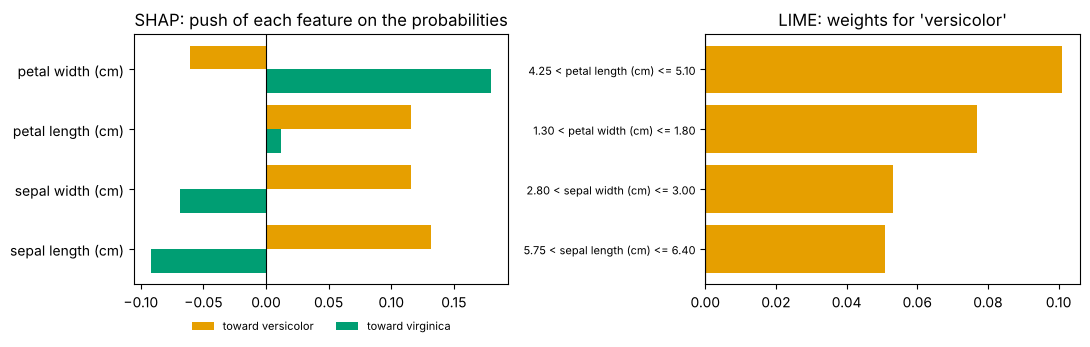

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

y_positions = np.arange(len(FEATURES))
axes[0].barh(y_positions + 0.2, local["versicolor"], height=0.4, color="#E69F00", label="toward versicolor")
axes[0].barh(y_positions - 0.2, local["virginica"], height=0.4, color="#009E73", label="toward virginica")
axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(FEATURES)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("SHAP: push of each feature on the probabilities")
axes[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)

order = lime_table.index[::-1]
axes[1].barh(range(len(order)), lime_table.loc[order, "weight"], color="#E69F00")
axes[1].set_yticks(range(len(order)))
axes[1].set_yticklabels(lime_table.loc[order, "condition"], fontsize=8)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("LIME: weights for 'versicolor'")

fig.tight_layout()
save_figure(fig, "04_local_explanations.png")
plt.show()

*Figure 2. What to notice:* the two tools tell different stories. SHAP's largest push toward *versicolor* comes from the sepal length, and its petal width bar points the other way; LIME's largest weights belong to the petal length and petal width. They differ in the *sign* for the petal width and in the ranking.

## 8. Do the explanations agree?

Let us compare the overall importance from permutation and from SHAP (average size of the SHAP values over all test flowers and classes).

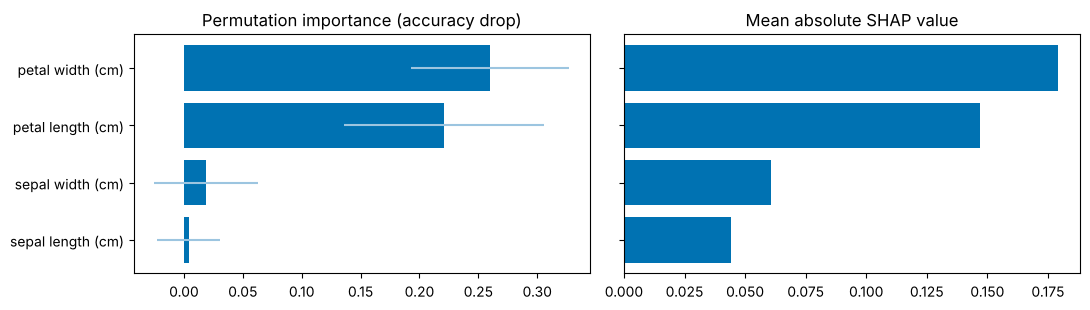

petal width (cm)     0.179
petal length (cm)    0.147
sepal width (cm)     0.061
sepal length (cm)    0.044


In [12]:
global_shap = pd.Series(np.abs(shap_values).mean(axis=(0, 2)), index=FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
order = perm["mean accuracy drop"].sort_values().index
axes[0].barh(order, perm.loc[order, "mean accuracy drop"], xerr=perm.loc[order, "spread"], color="#0072B2", ecolor="#9CC5E0")
axes[0].set_title("Permutation importance (accuracy drop)")
axes[1].barh(order, global_shap.loc[order], color="#0072B2")
axes[1].set_title("Mean absolute SHAP value")
fig.tight_layout()
save_figure(fig, "04_global_importance.png")
plt.show()
print(global_shap.round(3).sort_values(ascending=False).to_string())

*Figure 3. What to notice:* two very different methods rank the four measurements the same way: petal width, petal length, then the sepal ones far behind. That agreement is more convincing than either picture alone.

### Are LIME's answers stable?

LIME uses random variations. If we change the seed, does the explanation change? We repeat it for five seeds and look at the *order* of the features (strongest first).

In [13]:
rows = []
for seed in range(5):
    explainer_seed = LimeTabularExplainer(x_train.to_numpy(), feature_names=FEATURES, class_names=classes,
                                          discretize_continuous=True, random_state=seed)
    explanation = explainer_seed.explain_instance(flower.to_numpy()[0], predict_probabilities, num_features=4,
                                                  labels=[versicolor], num_samples=5000)
    ranking = [FEATURES[i].replace(" (cm)", "") for i, _ in explanation.as_map()[versicolor]]
    rows.append({"seed": seed, **{f"rank {r + 1}": name for r, name in enumerate(ranking)}})
pd.DataFrame(rows).set_index("seed")

,rank 1,rank 2,rank 3,rank 4
seed,,,,
0,petal width,petal length,sepal length,sepal width
1,petal width,petal length,sepal length,sepal width
2,petal width,petal length,sepal width,sepal length
3,petal width,petal length,sepal width,sepal length
4,petal width,petal length,sepal length,sepal width


The top two are always the two petal measurements (their order can flip: with seed 42 in section 7 the petal length came first), but the **third and fourth places swap** between seeds. So: trust LIME for the big picture, be careful with small differences, and report the seed.

## 9. What do we conclude?

For the mistaken flower:

- **Neighbours:** three flowers decide; the closest one was a *virginica*, but two *versicolor* outvoted it.
- **SHAP:** the sepal measurements pushed toward *versicolor*, the petal width toward *virginica*.
- **LIME:** petal width and petal length are the main factors; their signs differ from SHAP's for the petal width.

Different tools tell *different but compatible* stories, because they answer slightly different questions: SHAP compares with an average flower from the background data, LIME with a simple model fitted around the flower. The neighbours need no assumptions at all, which is a real advantage of KNN.

Two cautions. An explanation describes **the model**, not the truth about flowers. And a method that *sounds* convincing can still be unstable (LIME ranks) or depend on settings (SHAP's background data), so check agreement and say which settings you used.

## 10. Check yourself

**Question 1.** Why can KNN explain a prediction with no extra tool, when a random forest cannot?

<details>
<summary>Show the answer</summary>

KNN's decision is literally a vote among the nearest stored examples, so showing those examples *is* the explanation. A random forest combines hundreds of trees; no short list of examples or rules summarises that.

</details>

**Question 2.** SHAP says one feature pushed *against* the prediction and LIME says it pushed *for* it. Is one of them wrong?

<details>
<summary>Show the answer</summary>

Not necessarily. They compare with different references (an average over background data versus a local simple model), and LIME's discretised ranges and random sampling add differences. When two tools disagree, look at a third source (here: the neighbours) and be cautious about small effects.

</details>

**Question 3 (exercise).** Change `case = int(mistakes[0])` to `int(mistakes[1])` to study the second mistake. Does the same measurement type dominate?

<details>
<summary>Show the answer</summary>

Run it and compare the neighbour table and the SHAP columns. Whatever you find, describe it in the same three steps: neighbours, SHAP, LIME, and say where they agree.

</details>

## 11. Common mistakes

- **Treating an explanation as a cause.** It tells you how the *model* decides, not why the flower is what it is.
- **Using one tool and one run.** Compare tools; for LIME, change the seed.
- **Forgetting the settings.** SHAP depends on the background data, LIME on the neighbourhood and the bins.
- **Explaining only the right answers.** The mistakes are where explanations teach the most.

## 12. Recap

- KNN is explained by its **neighbours**; **permutation importance** gives the global picture; **SHAP** and **LIME** explain single decisions.
- On Iris all methods agree that the **petal measurements matter most**; they can disagree on the details of one flower.
- Check **agreement and stability**, and always state the settings and the seed.

**Next:** this lesson is complete. The original 2022 script is still in `legacy/`; the README compares then and now.

### Further reading
- S. M. Lundberg and S.-I. Lee (2017), *A unified approach to interpreting model predictions*, Advances in Neural Information Processing Systems 30 (the SHAP paper).
- M. T. Ribeiro, S. Singh and C. Guestrin (2016), *"Why should I trust you?": Explaining the predictions of any classifier*, KDD 2016 (the LIME paper).
- SHAP documentation: https://shap.readthedocs.io
- LIME repository and documentation: https://github.com/marcotcr/lime
- scikit-learn user guide, *Permutation feature importance*: https://scikit-learn.org/stable/modules/permutation_importance.html